<a href="https://colab.research.google.com/github/oecarvalho/idhm_analise/blob/main/idhm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## IDHM - Índice de Desenvolvimento Humano Municipal


O IDHM é uma medida composta por 3 indicadores que dimensionam o desenvolvimento humano: longevidade, educação e renda. O índice varia de 0 a 1, sendo que quanto mais próximo de 1, maior o desenvolvimento humano.

**Pergunta Norteadora:** Quais são os estados que possuem um IDH bom para que possamos entregar bons produtos?

In [1]:
### Instalando a lib que facilita a leitura de arquivos xls.
!pip install xlrd openpyxl

In [2]:
#Libs que serão usadas para exploração e manipulação de dados
import pandas as pd
import numpy as np

#Libs gráficas
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


#Ignorando Avisos desnecessários
import warnings
warnings.filterwarnings('ignore')

In [3]:
idhm = pd.read_excel('/content/drive/MyDrive/Data Science/Pos_tech/Fase 1/IDHM/IDH_2010.xls')
idhm.head()

,ANO,Código da Unidade da Federação,Nome da Unidade da Federação,Código do Município,Município,Esperança de vida ao nascer,Taxa de fecundidade total,Mortalidade infantil,Mortalidade até 5 anos de idade,Razão de dependência,...,População de 15 a 17 anos.1,População de 18 anos ou mais.1,População total em domicílios particulares permanentes,"População total em domicílios particulares permanentes, exceto com renda nula",Subíndice de escolaridade - IDHM Educação,Subíndice de frequência escolar - IDHM Educação,IDHM,IDHM Educação,IDHM Longevidade,IDHM Renda
0,2010,11,Rondônia,110001,ALTA FLORESTA D'OESTE,70.75,2.24,23.8,25.49,47.37,...,1602,16431,24097,22429,0.368,0.629,0.641,0.526,0.763,0.657
1,2010,11,Rondônia,110002,ARIQUEMES,73.36,1.91,19.2,20.53,46.68,...,5256,60213,89766,88730,0.514,0.648,0.702,0.600,0.806,0.716
2,2010,11,Rondônia,110003,CABIXI,70.39,2.15,24.8,26.58,48.12,...,381,4306,6303,6156,0.357,0.700,0.650,0.559,0.757,0.650
3,2010,11,Rondônia,110004,CACOAL,74.27,1.90,14.3,15.38,43.79,...,4547,54356,78141,76876,0.488,0.698,0.718,0.620,0.821,0.727
4,2010,11,Rondônia,110005,CEREJEIRAS,72.94,2.12,18.1,19.42,45.67,...,1033,11786,16942,16815,0.430,0.712,0.692,0.602,0.799,0.688


Quando fazemos a busca pelos 5 primeiros registros da base, entendemos que a mesma nos traz diversas informações que são relevantes para a composição do IDHM, contendo inclusive, o resultado do IDHM, assim como também o IDHM por cada categoria.

Uma atenção especial deve ser dada para os 3 pontinhos (...) que aparecem no meio das "colunas", pois isso indica que temos outras informações pertinentes nessas colunas que não foram expostas. Para entender mais sobre a nossa base, vamos aplicar outros métodos que nos permite explorar as informações

## Tamanho da base

In [4]:
### Verificando o tamanho da nossa base de dados usando o "shape", que nos permite ver a seguinte informação: (registros, colunas)
idhm.shape

(5564, 237)

In [5]:
### Verificando os tipos de dados
idhm.dtypes

,0
ANO,int64
Código da Unidade da Federação,int64
Nome da Unidade da Federação,object
Código do Município,int64
Município,object
...,...
Subíndice de frequência escolar - IDHM Educação,float64
IDHM,float64
IDHM Educação,float64
IDHM Longevidade,float64


In [6]:
#Verificando se existe valores nulos na nossa base
idhm.isnull().sum()

,0
ANO,0
Código da Unidade da Federação,0
Nome da Unidade da Federação,0
Código do Município,0
Município,0
...,...
Subíndice de frequência escolar - IDHM Educação,0
IDHM,0
IDHM Educação,0
IDHM Longevidade,0


Como no exemplo anterior verificamos que não existe de maneira "geral" valores nulos, podemos fazer a soma de todos os resultados para atestar que de fato não existem valores nulos na tabela.

In [7]:
### Constatando que de fato não existe valores nulos na tabela.
idhm.isnull().sum().sum()

np.int64(0)

Verificado que não temos valores nulos dentro da nossa base, podemos fazer agora a verificação de quais colunas e informações serão relevantes para o nosso estudo.

Como já foi possível observar, **temos 237 colunas** nessa tabela, entretanto, precisamos voltar para a nossa pergunta de norteadora e verificar de fato quais informações presentes nas colunas serão úteis para nossa analise.

**Pergunta Norteadora:** Quais são os estados que possuem um IDH bom para que possamos entregar bons produtos?

Olhando para a nossa pergunta, podemos determinar que serão utilizadas colunas que tragam informações sobre o valor de IDH e localização (estado, município...)

In [8]:
idhm.columns

Index(['ANO', 'Código da Unidade da Federação', 'Nome da Unidade da Federação',
       'Código do Município', 'Município', 'Esperança de vida ao nascer',
       'Taxa de fecundidade total', 'Mortalidade infantil',
       'Mortalidade até 5 anos de idade', 'Razão de dependência',
       ...
       'População de 15 a 17 anos.1', 'População de 18 anos ou mais.1',
       'População total em domicílios particulares permanentes',
       'População total em domicílios particulares permanentes, exceto com renda nula',
       'Subíndice de escolaridade - IDHM Educação',
       'Subíndice de frequência escolar - IDHM Educação', 'IDHM',
       'IDHM Educação', 'IDHM Longevidade', 'IDHM Renda'],
      dtype='object', length=237)

Podemos ver que temos colunas que falam sobre mortalidade, fecundidade, faixa etária, frequência escolar... entre outras informações. Porém nossa pergunta norteadora quer apenas dados que dizem respeito a localização e ao IDH.

Se olharmos nas nossas colunas, verificamos que temos informações sobre:


*   Nome da Unidade da federação (estado)
*   Município
*   IDHM por município
*   IDHM estratificado (Educação, Longevidade, Renda)

Acredito então que esses serão os dados necessários para que possamos fazer a análise que a pergunta norteadora exige. Note que de 237 colunas, vamos precisar apenas de 6~10 colunas para a análise.

Portanto, vamos fazer a remoção das colunas necessárias e inserir elas em um novo dataframe.


In [9]:
### Removendo apenas as colunas que serão necessárias para a nossa análise

df_idhm = idhm[['Nome da Unidade da Federação', 'Município', 'IDHM', 'IDHM Educação', 'IDHM Longevidade', 'IDHM Renda']]
df_idhm.head()

,Nome da Unidade da Federação,Município,IDHM,IDHM Educação,IDHM Longevidade,IDHM Renda
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688


Uma boa prática em dados é fazer uma alteração em nomes complexos como estão os das colunas da tabela. Note que elas possuem Caixa alta e baixa, espaços, acentos, cedilhas... Desta forma, é interessante normalizarmos os nomes das colunas.

In [10]:
### alterando o nome das colunas.

df_idhm.columns = ['uf', 'municipio', 'idhm', 'idhm_educacao', 'idhm_longevidade', 'idhm_renda']
df_idhm.head()

,uf,municipio,idhm,idhm_educacao,idhm_longevidade,idhm_renda
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688


In [11]:
## verificando se não houve alguma alteração na base de dados
df_idhm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5564 entries, 0 to 5563
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   uf                5564 non-null   object 
 1   municipio         5564 non-null   object 
 2   idhm              5564 non-null   float64
 3   idhm_educacao     5564 non-null   float64
 4   idhm_longevidade  5564 non-null   float64
 5   idhm_renda        5564 non-null   float64
dtypes: float64(4), object(2)
memory usage: 260.9+ KB


In [12]:
# Verificando os valores únicos

df_idhm.nunique()

,0
uf,27
municipio,5329
idhm,349
idhm_educacao,466
idhm_longevidade,220
idhm_renda,390


Chegamos ao final da verificação. Até o momento fizemos:


*   Verificação do tamanho da base
*   Verificamos os tipos de dados presentes na tabela
*   Verificamos a existência de valores nulos
*   Verificamos quais valores utilizaremos na análise com base na pergunta norteadora
*   Extraimos os dados que vamos usar na análise para um novo dataframe
*   Normalizamos os nomes das colunas do novo dataframe
*   Verificamos se houve mudanças nos valores presentes na tabela
*   Verificamos a quantidade de valores únicos por coluna




## Estatistica Descritiva

Essa etapa serve para fazermos as primeiras análises relacionadas aos dados que acabamos de coletar.

In [13]:
df_idhm.describe().round(2)

,idhm,idhm_educacao,idhm_longevidade,idhm_renda
count,5564.00,5564.00,5564.00,5564.00
mean,0.66,0.56,0.80,0.64
std,0.07,0.09,0.04,0.08
min,0.42,0.21,0.67,0.40
25%,0.60,0.49,0.77,0.57
50%,0.66,0.56,0.81,0.65
75%,0.72,0.63,0.84,0.71
max,0.86,0.82,0.89,0.89


Ao observar a tabela acima, podemos conferir a contagem exata de registros que temos na tabela, assim como também a media dos valores de cada coluna, como os valores, minimos, máximos e médios da tabela.

Classificação do IDHM:

*   0 - 0,499 -> Baixo Desenvolvimento Humano
*   0,5 - 0,799 -> Médio Desenvolvimento Humano
*   0,8 - 1 -> Alto Desenvolvimento Humano



In [14]:
# Função de classificação IDHM

def idhm_class(df):
  if df['idhm'] <= 0.499:
    return 'Baixo Desenvolvimento Humano'
  elif df['idhm'] >= 0.5 and df['idhm'] <= 0.799:
    return 'Médio Desenvolvimento Humano'
  else:
    return 'Alto Desenvolvimento Humano'

In [15]:
df_idhm['classe'] = df_idhm.apply(idhm_class, axis=1)
df_idhm


,uf,municipio,idhm,idhm_educacao,idhm_longevidade,idhm_renda,classe
0,Rondônia,ALTA FLORESTA D'OESTE,0.641,0.526,0.763,0.657,Médio Desenvolvimento Humano
1,Rondônia,ARIQUEMES,0.702,0.600,0.806,0.716,Médio Desenvolvimento Humano
2,Rondônia,CABIXI,0.650,0.559,0.757,0.650,Médio Desenvolvimento Humano
3,Rondônia,CACOAL,0.718,0.620,0.821,0.727,Médio Desenvolvimento Humano
4,Rondônia,CEREJEIRAS,0.692,0.602,0.799,0.688,Médio Desenvolvimento Humano
...,...,...,...,...,...,...,...
5559,Goiás,VIANÓPOLIS,0.712,0.622,0.818,0.710,Médio Desenvolvimento Humano
5560,Goiás,VICENTINÓPOLIS,0.684,0.562,0.804,0.707,Médio Desenvolvimento Humano
5561,Goiás,VILA BOA,0.647,0.534,0.818,0.619,Médio Desenvolvimento Humano
5562,Goiás,VILA PROPÍCIO,0.634,0.505,0.802,0.629,Médio Desenvolvimento Humano


Criamos uma função que ferifica o valor do IDHM por cidade e classifica a cidade por baixo, médio e alto desenvolvimento humano. Com isso, criamos uma nova coluna no nosso dataframe chamada "classe" e atribuimos a função a mesma, onde foi feita a verificação dos valores e feito a classificação.

Pudemos verificar que foi aplicado a cada cidade uma classificação com base no valor do seu IDHM, agora, falta fazermos a contagem de cada classificação para sabermos quantas cidades de alta, média e baixo IDHM nós temos na tabela.

In [16]:
df_idhm['classe'].value_counts()

,count
classe,
Médio Desenvolvimento Humano,5488
Alto Desenvolvimento Humano,44
Baixo Desenvolvimento Humano,32


Conseguimos verificar que temos majoritariamente, cidades de médio desenvolvimento humano. Entretanto, seria interessante trazermos essa visualização por meio de um gráfico.

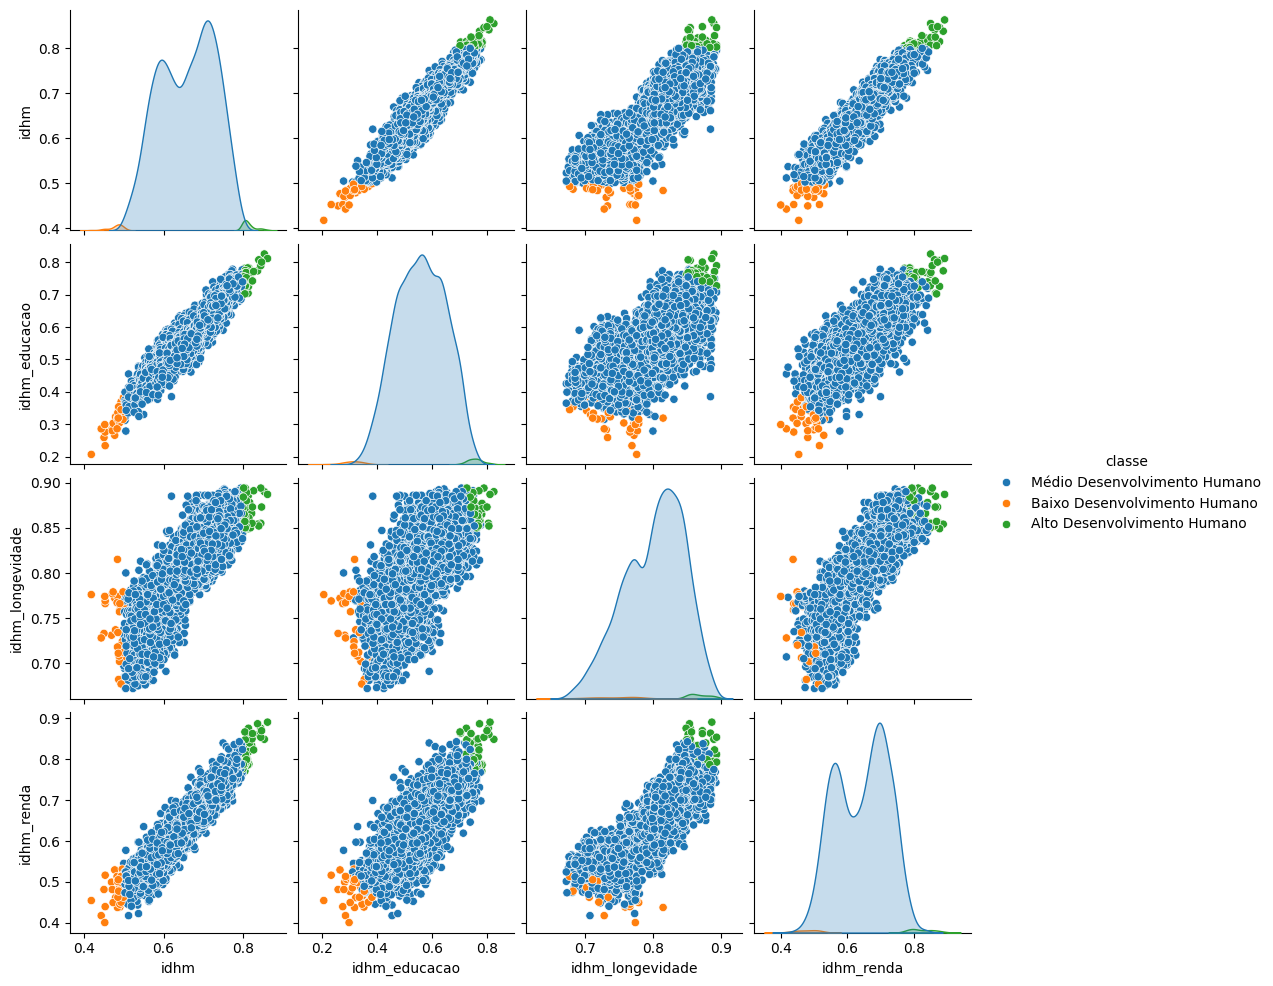

In [17]:
sns.pairplot(df_idhm, hue='classe')

Pontos de observação:
* Aparentemente existe relação entre renda e escolaridade

Agora que temos os dados separados e a classificação feita, o próximo passo seria verificarmos o comportamento dos dados por estado, tendo em vista que é o que a nossa pergunta norteadora pede.

In [18]:
#Para isso, vamos criar um novo dataframe contendo apenas os estados e o IDHM
df_idhm_estado = pd.DataFrame(df_idhm.groupby('uf')['idhm'].mean().round(2))
df_idhm_estado

,idhm
uf,
Acre,0.59
Alagoas,0.56
Amapá,0.64
Amazonas,0.57
Bahia,0.59
Ceará,0.62
Distrito Federal,0.82
Espírito Santo,0.69
Goiás,0.69


In [19]:
df_idhm_estado['classe'] = df_idhm_estado.apply(idhm_class, axis=1)
df_idhm_estado


,idhm,classe
uf,,
Acre,0.59,Médio Desenvolvimento Humano
Alagoas,0.56,Médio Desenvolvimento Humano
Amapá,0.64,Médio Desenvolvimento Humano
Amazonas,0.57,Médio Desenvolvimento Humano
Bahia,0.59,Médio Desenvolvimento Humano
Ceará,0.62,Médio Desenvolvimento Humano
Distrito Federal,0.82,Alto Desenvolvimento Humano
Espírito Santo,0.69,Médio Desenvolvimento Humano
Goiás,0.69,Médio Desenvolvimento Humano


In [20]:
df_idhm_estado = df_idhm_estado.reset_index()

# Remove qualquer coluna extra criada pelo reset_index (ex: 'index' ou 'level_0')
df_idhm_estado = df_idhm_estado.drop(columns=["index", "level_0"], errors="ignore")

# Garante a ordem exata das colunas
df_idhm_estado = df_idhm_estado[["uf", "idhm", "classe"]]

df_idhm_estado

,uf,idhm,classe
0,Acre,0.59,Médio Desenvolvimento Humano
1,Alagoas,0.56,Médio Desenvolvimento Humano
2,Amapá,0.64,Médio Desenvolvimento Humano
3,Amazonas,0.57,Médio Desenvolvimento Humano
4,Bahia,0.59,Médio Desenvolvimento Humano
5,Ceará,0.62,Médio Desenvolvimento Humano
6,Distrito Federal,0.82,Alto Desenvolvimento Humano
7,Espírito Santo,0.69,Médio Desenvolvimento Humano
8,Goiás,0.69,Médio Desenvolvimento Humano
9,Maranhão,0.58,Médio Desenvolvimento Humano


In [21]:
df_idhm_estado['classe'].value_counts()

,count
classe,
Médio Desenvolvimento Humano,26
Alto Desenvolvimento Humano,1


In [22]:
df_idhm_estado.describe().round(2)

,idhm
count,27.00
mean,0.64
std,0.06
min,0.56
25%,0.59
50%,0.64
75%,0.69
max,0.82


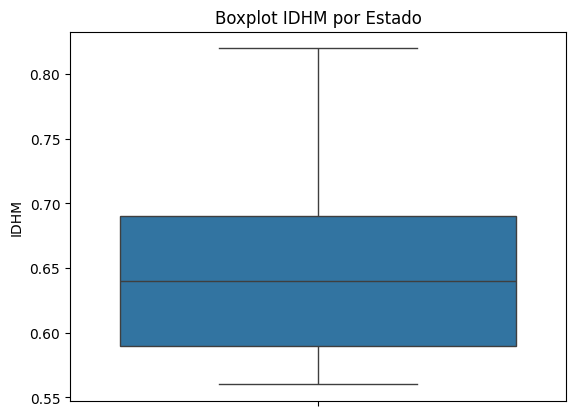

In [23]:
#usando o gráfico de boxplot para analisarmos possiveis outliers
sns.boxplot(y = df_idhm_estado['idhm'], data = df_idhm_estado)

#adicionando titulo e rótulos para os eixos do gráfico
plt.title('Boxplot IDHM por Estado')
plt.ylabel('IDHM');



*   25% dos dados estão dentro da faixa de 0.59
*   50% da nossa base são compostos por valores que compreendem 0.64
*   75% se encontra com valores proximos a 0.69
*   de 0.69 até 0.82, temos valores que não foram explorados.





## Utilizando gráficos para gerar insights

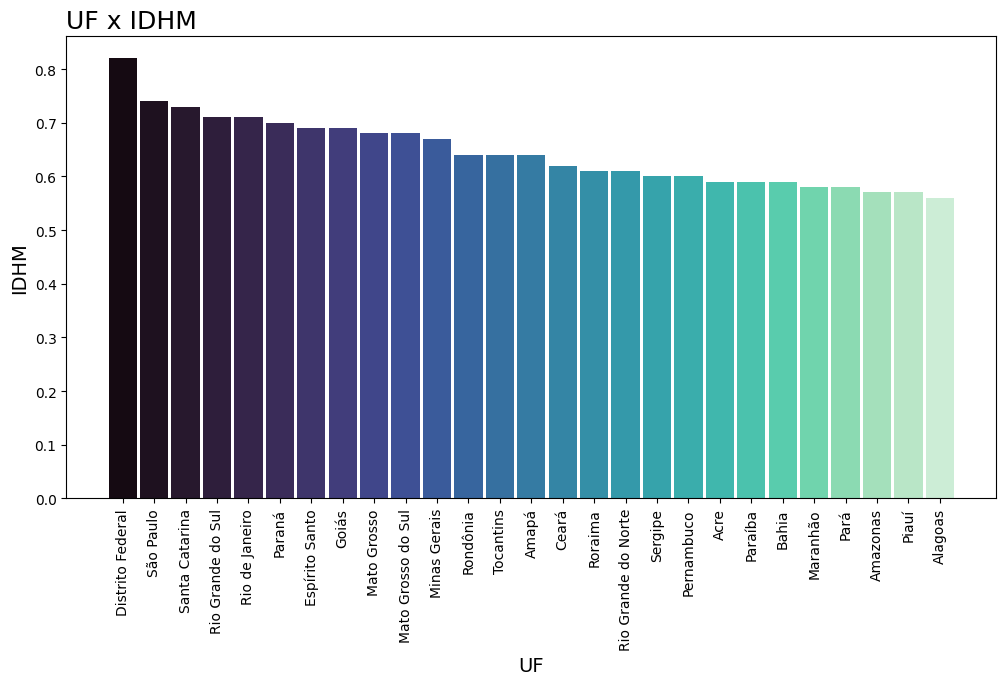

In [24]:
df_idhm_estado = df_idhm_estado.sort_values(by='idhm', ascending=False)

#Tamanho do gráfico
plt.figure(figsize=(12, 6))

# Paletas de cores
Paleta_Cores = sns.color_palette('mako', len(df_idhm_estado))

# Plotagem do gráfico
plt.bar(df_idhm_estado['uf'],
        df_idhm_estado['idhm'],
        width=0.9,
        color = Paleta_Cores
        )

# Titulo
plt.title('UF x IDHM', loc= 'left', fontsize=18)

#labels
plt.xlabel('UF', fontsize = 14)
plt.ylabel('IDHM', fontsize = 14)
plt.xticks(rotation=90);

In [25]:
#Criando gráfico com plotly

fig = px.bar(df_idhm_estado,
            x='uf',
            y='idhm',
            color='classe',
            title= 'IDHM por Estado',
            color_discrete_sequence=['green', 'orange'])
fig.show()

In [27]:
# Mapeando nome do estado -> região

mapa_regiao_nome = {
    "Acre": "Norte",
    "Amapá": "Norte",
    "Amazonas": "Norte",
    "Pará": "Norte",
    "Rondônia": "Norte",
    "Roraima": "Norte",
    "Tocantins": "Norte",

    "Alagoas": "Nordeste",
    "Bahia": "Nordeste",
    "Ceará": "Nordeste",
    "Maranhão": "Nordeste",
    "Paraíba": "Nordeste",
    "Pernambuco": "Nordeste",
    "Piauí": "Nordeste",
    "Rio Grande do Norte": "Nordeste",
    "Sergipe": "Nordeste",

    "Distrito Federal": "Centro-Oeste",
    "Goiás": "Centro-Oeste",
    "Mato Grosso": "Centro-Oeste",
    "Mato Grosso do Sul": "Centro-Oeste",

    "Espírito Santo": "Sudeste",
    "Minas Gerais": "Sudeste",
    "Rio de Janeiro": "Sudeste",
    "São Paulo": "Sudeste",

    "Paraná": "Sul",
    "Rio Grande do Sul": "Sul",
    "Santa Catarina": "Sul",
}

df_idhm["regiao"] = df_idhm["uf"].map(mapa_regiao_nome)

df_idhm[["uf", "regiao"]].drop_duplicates().sort_values("regiao")

,uf,regiao
5563,Distrito Federal,Centro-Oeste
5176,Mato Grosso,Centro-Oeste
5098,Mato Grosso do Sul,Centro-Oeste
5317,Goiás,Centro-Oeste
1825,Bahia,Nordeste
1750,Sergipe,Nordeste
1463,Pernambuco,Nordeste
1240,Paraíba,Nordeste
1073,Rio Grande do Norte,Nordeste
1648,Alagoas,Nordeste


In [28]:
idhm_regiao = df_idhm.groupby("regiao")["idhm"].mean().sort_values()
idhm_regiao

,idhm
regiao,
Nordeste,0.590672
Norte,0.607951
Centro-Oeste,0.689468
Sudeste,0.698984
Sul,0.714113


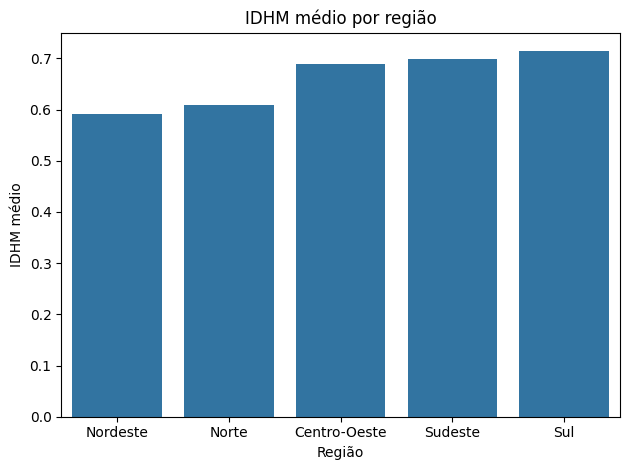

In [29]:
plt.figure()
sns.barplot(x=idhm_regiao.index, y=idhm_regiao.values)
plt.title("IDHM médio por região")
plt.xlabel("Região")
plt.ylabel("IDHM médio")
plt.tight_layout()
plt.show()

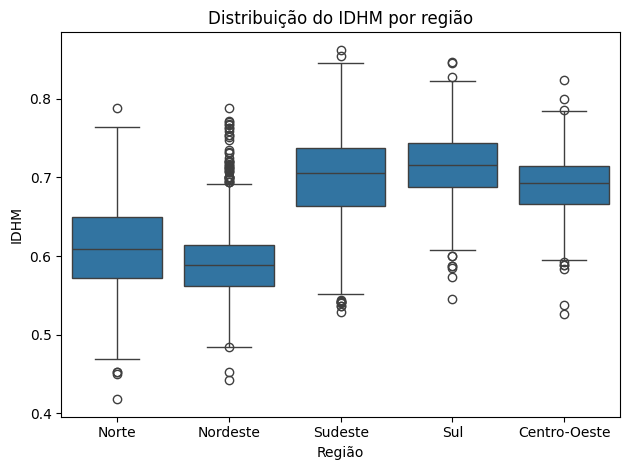

In [30]:
plt.figure()
sns.boxplot(data=df_idhm, x="regiao", y="idhm") #municipio
plt.title("Distribuição do IDHM por região")
plt.xlabel("Região")
plt.ylabel("IDHM")
plt.tight_layout()
plt.show()

In [31]:
# 9.1 Maiores e Menores N municípios por IDHM

N = 10

if "municipio" in df_idhm.columns:
    maiores = df_idhm.sort_values("idhm", ascending=False).head(N)[["municipio", "uf", "idhm","regiao"]].copy()
    menores = df_idhm.sort_values("idhm", ascending=True).head(N)[["municipio", "uf", "idhm","regiao"]].copy()
else:
    maiores = df_idhm.sort_values("idhm", ascending=False).head(N)[["uf", "idhm"]].copy()
    menores = df_idhm.sort_values("idhm", ascending=True).head(N)[["uf", "idhm"]].copy()

# Criar coluna indicando se é Top ou Bottom
maiores["tipo"] = "Maiores"
menores["tipo"] = "Menores"

# Unir tudo em um único DataFrame
ranking_idhm = pd.concat([maiores, menores], axis=0).reset_index(drop=True)

ranking_idhm

,municipio,uf,idhm,regiao,tipo
0,SÃO CAETANO DO SUL,São Paulo,0.862,Sudeste,Maiores
1,ÁGUAS DE SÃO PEDRO,São Paulo,0.854,Sudeste,Maiores
2,FLORIANÓPOLIS,Santa Catarina,0.847,Sul,Maiores
3,VITÓRIA,Espírito Santo,0.845,Sudeste,Maiores
4,BALNEÁRIO CAMBORIÚ,Santa Catarina,0.845,Sul,Maiores
5,SANTOS,São Paulo,0.840,Sudeste,Maiores
6,NITERÓI,Rio de Janeiro,0.837,Sudeste,Maiores
7,JOAÇABA,Santa Catarina,0.827,Sul,Maiores
8,BRASÍLIA,Distrito Federal,0.824,Centro-Oeste,Maiores
9,CURITIBA,Paraná,0.823,Sul,Maiores


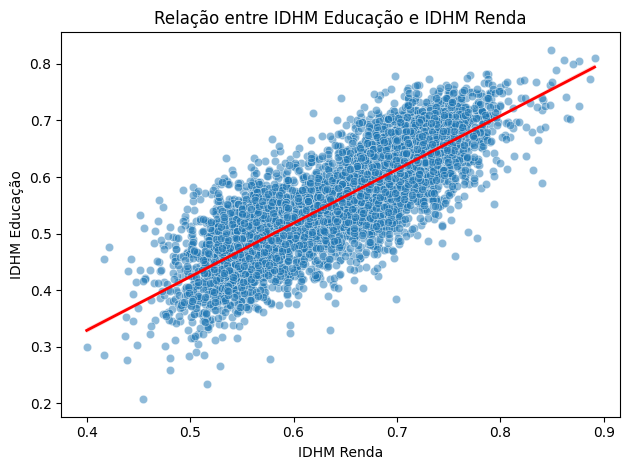

In [32]:
sns.scatterplot(data=df_idhm, x="idhm_renda", y="idhm_educacao", alpha=0.5)

# Linha de tendência com regplot
sns.regplot(
         data=df_idhm,
        x="idhm_renda",
        y="idhm_educacao",
        scatter=False,            # não recria os pontos
        color="red",              # linha de tendência em vermelho
        line_kws={"linewidth": 2} # deixa a linha mais grossa
    )

plt.title("Relação entre IDHM Educação e IDHM Renda")
plt.xlabel("IDHM Renda")
plt.ylabel("IDHM Educação")
plt.tight_layout()
plt.show()

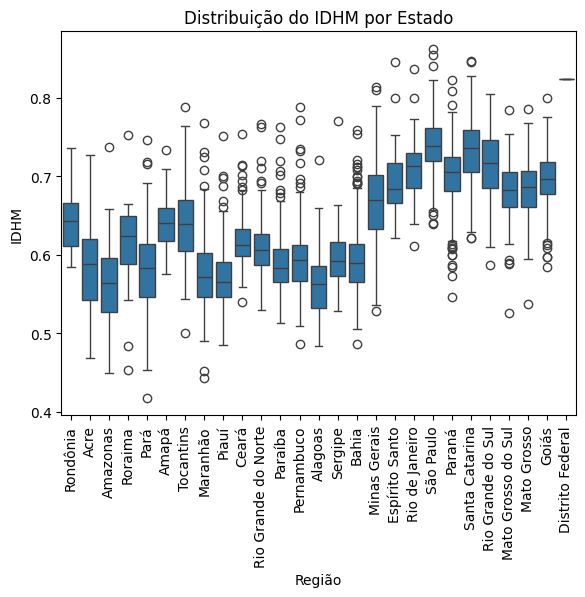

In [34]:
#Boxsplot por estado
plt.figure()
sns.boxplot(data=df_idhm, x="uf", y="idhm") #municipio
plt.title("Distribuição do IDHM por Estado")
plt.xlabel("Região")
plt.ylabel("IDHM")
plt.tight_layout()
plt.xticks(rotation = 90);
plt.show()

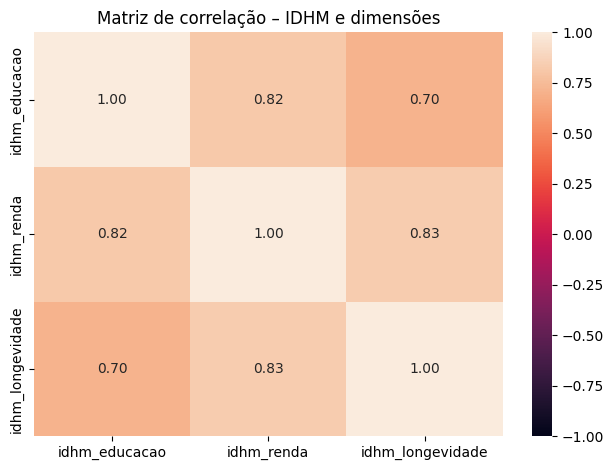

In [35]:
cols_corr = [c for c in ["idhm_educacao", "idhm_renda", "idhm_longevidade"] if c in df_idhm.columns]
corr = df_idhm[cols_corr].corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="rocket", vmin=-1, vmax=1)
plt.title("Matriz de correlação – IDHM e dimensões")
plt.tight_layout()
plt.show()

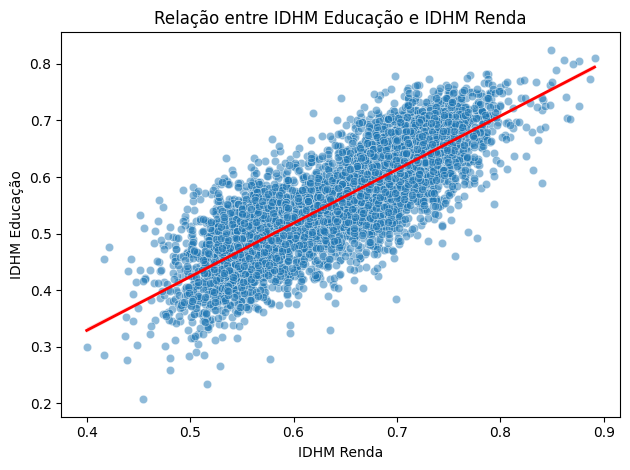

In [36]:
sns.scatterplot(data=df_idhm, x="idhm_renda", y="idhm_educacao", alpha=0.5)

# Linha de tendência com regplot
sns.regplot(
         data=df_idhm,
        x="idhm_renda",
        y="idhm_educacao",
        scatter=False,            # não recria os pontos
        color="red",              # linha de tendência em vermelho
        line_kws={"linewidth": 2} # deixa a linha mais grossa
    )

plt.title("Relação entre IDHM Educação e IDHM Renda")
plt.xlabel("IDHM Renda")
plt.ylabel("IDHM Educação")
plt.tight_layout()
plt.show()